In [1]:
# Here I will perform the same models as in the previous file
# rather than extracting text statistics, I will use Tf Idf Vectorization

import kagglehub
import os
import pandas as pd


path = kagglehub.dataset_download("shanegerami/ai-vs-human-text")
print(" Dataset downloaded to:", path)

csv_path = None
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_path = os.path.join(root, f)

if csv_path is None:
    raise FileNotFoundError("CSV not found!")

print("Found CSV:", csv_path)

df = pd.read_csv(csv_path)

print("\nDataset loaded")
print(df.head())
print("\nClass distribution:  0 (Human), 1(AI generated)")
print(df["generated"].value_counts())

#Balancing the dataset

ai_written=df[df["generated"]== 1].sample(5000, random_state=42)
human_written = df[df["generated"] == 0].sample(5000, random_state=42)

balanced_dataset=pd.concat([ai_written, human_written]).sample(frac=1,random_state=42)

print(balanced_dataset["generated"].value_counts())
print(balanced_dataset.head())



 Dataset downloaded to: C:\Users\xhani\.cache\kagglehub\datasets\shanegerami\ai-vs-human-text\versions\1
Found CSV: C:\Users\xhani\.cache\kagglehub\datasets\shanegerami\ai-vs-human-text\versions\1\AI_Human.csv

Dataset loaded
                                                text  generated
0  Cars. Cars have been around since they became ...        0.0
1  Transportation is a large necessity in most co...        0.0
2  "America's love affair with it's vehicles seem...        0.0
3  How often do you ride in a car? Do you drive a...        0.0
4  Cars are a wonderful thing. They are perhaps o...        0.0

Class distribution:  0 (Human), 1(AI generated)
generated
0.0    305797
1.0    181438
Name: count, dtype: int64
generated
0.0    5000
1.0    5000
Name: count, dtype: int64
                                                     text  generated
269265  Dear Principal,\n\nWe have been hearing quite ...        0.0
327273   Dear [State Senator],\n\nI am writing to expr...        1.0
167398  As

In [2]:
from sklearn.model_selection import train_test_split

X=balanced_dataset["text"]
y=balanced_dataset["generated"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [3]:
#TF IDF Vectorization
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vec=TfidfVectorizer(max_features=20000,ngram_range=(1,2),stop_words="english")
X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_test_tfidf  = tfidf_vec.transform(X_test)

print("TF-IDF train shape:", X_train_tfidf.shape)
print("TF-IDF test shape :", X_test_tfidf.shape)

TF-IDF train shape: (8000, 20000)
TF-IDF test shape : (2000, 20000)


Criterion=gini | Depth=1 |Leaf= 1 | Accuracy=0.6255
Criterion=gini | Depth=2 |Leaf= 1 | Accuracy=0.6990
Criterion=gini | Depth=3 |Leaf= 1 | Accuracy=0.7435
Criterion=gini | Depth=5 |Leaf= 1 | Accuracy=0.7715
Criterion=gini | Depth=10 |Leaf= 1 | Accuracy=0.8445
Criterion=gini | Depth=None |Leaf= 1 | Accuracy=0.8680


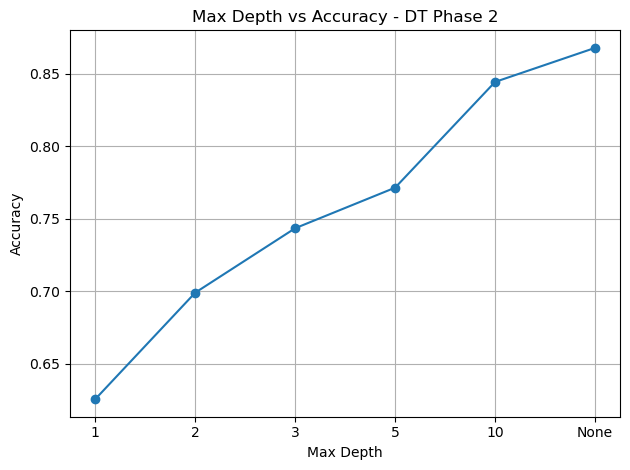

Criterion= gini | Depth=None | Leaf=1 | Accuracy=0.8680
Criterion= gini | Depth=None | Leaf=2 | Accuracy=0.8665
Criterion= gini | Depth=None | Leaf=5 | Accuracy=0.8635
Criterion= gini | Depth=None | Leaf=10 | Accuracy=0.8695
Criterion= gini | Depth=None | Leaf=20 | Accuracy=0.8580
Criterion= gini | Depth=None | Leaf=50 | Accuracy=0.8500


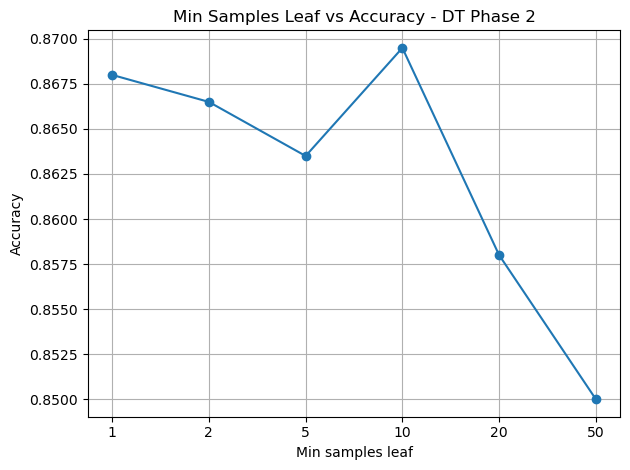

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

depth_testing=[1,2,3,5,10,None]
leaves=[1,2,5,10,20,50]
criterion="gini"
accuracy_arr=[]
for d in depth_testing:
    dt_tfidf = DecisionTreeClassifier(max_depth=d,random_state=42)
    dt_tfidf.fit(X_train_tfidf, y_train)
    preds = dt_tfidf.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, preds)  
    accuracy_arr.append(accuracy)  
    print(f"Criterion=gini | Depth={d} |Leaf= 1 | Accuracy={accuracy:.4f}")    

plt.figure()
plt.plot([str(d) for d in depth_testing],accuracy_arr,marker="o")
plt.title("Max Depth vs Accuracy - DT Phase 2")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

accuracy_arr1=[]
for l in leaves:
    tree = DecisionTreeClassifier(min_samples_leaf=l,random_state=42)

    tree.fit(X_train_tfidf,y_train)
    preds = tree.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, preds)  
    accuracy_arr1.append(accuracy)  
    print(f"Criterion= gini | Depth=None | Leaf={l} | Accuracy={accuracy:.4f}")    

plt.figure()
plt.plot([str(l) for l in leaves],accuracy_arr1,marker="o")
plt.title("Min Samples Leaf vs Accuracy - DT Phase 2")
plt.xlabel("Min samples leaf")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

 Nr of trees:100, Nr of leaves:1 Acc: 0.9675
 Nr of trees:100, Nr of leaves:2 Acc: 0.968
 Nr of trees:100, Nr of leaves:5 Acc: 0.9605
 Nr of trees:100, Nr of leaves:10 Acc: 0.9545
 Nr of trees:100, Nr of leaves:20 Acc: 0.942


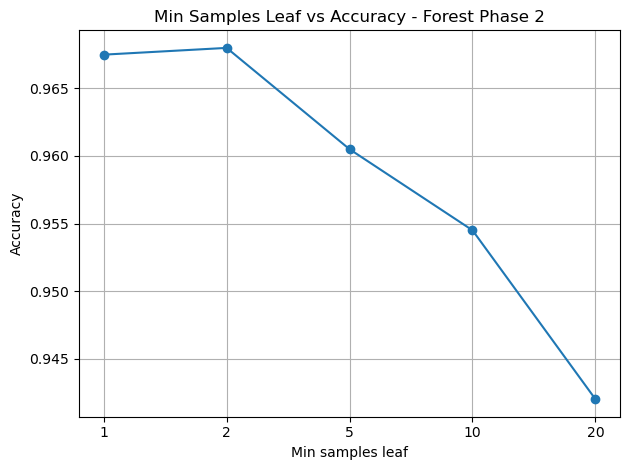

 Nr of trees:10, Nr of leaves:1 Acc: 0.935
 Nr of trees:50, Nr of leaves:1 Acc: 0.967
 Nr of trees:100, Nr of leaves:1 Acc: 0.9675
 Nr of trees:250, Nr of leaves:1 Acc: 0.97
 Nr of trees:500, Nr of leaves:1 Acc: 0.97


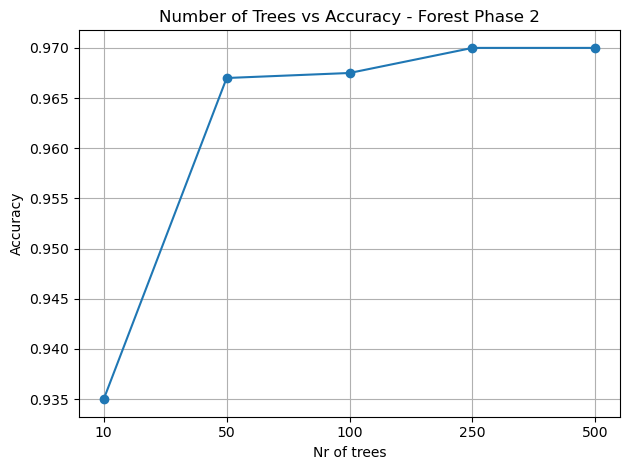

In [10]:
from sklearn.ensemble import RandomForestClassifier
nr_trees=[10,50,100,250,500]
leaves=[1,2,5,10,20]
accuracy_rf=[]
accuracy_rf2=[]
for l in leaves:
    forest=RandomForestClassifier(n_estimators=100,criterion='gini',max_depth=None,min_samples_leaf=l,random_state=42)
    forest.fit(X_train_tfidf,y_train)
    rf_preds=forest.predict(X_test_tfidf)
    rf_acc=accuracy_score(y_test,rf_preds)
    accuracy_rf.append(rf_acc)
    print(f" Nr of trees:100, Nr of leaves:{l} Acc: {rf_acc}")

plt.figure()
plt.plot([str(l) for l in leaves],accuracy_rf,marker="o")
plt.title("Min Samples Leaf vs Accuracy - Forest Phase 2")
plt.xlabel("Min samples leaf")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

for no in nr_trees:   
    forest=RandomForestClassifier(n_estimators=no,criterion='gini',max_depth=None,min_samples_leaf=1,random_state=42)
    forest.fit(X_train_tfidf,y_train)
    rf_preds=forest.predict(X_test_tfidf)
    rf_acc=accuracy_score(y_test,rf_preds)
    accuracy_rf2.append(rf_acc)
    print(f" Nr of trees:{no}, Nr of leaves:1 Acc: {rf_acc}")

plt.figure()
plt.plot([str(no) for no in nr_trees],accuracy_rf2,marker="o")
plt.title("Number of Trees vs Accuracy - Forest Phase 2")
plt.xlabel("Nr of trees")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm = SVC(kernel='rbf',C=10,gamma='scale')
svm.fit(X_train_tfidf, y_train)

preds = svm.predict(X_test_tfidf)

print("SVM Accuracy:", round(accuracy_score(y_test, preds),4))

#from sklearn.svm import LinearSVC
#from sklearn.metrics import accuracy_score

#svm = LinearSVC(C=10)
#svm.fit(X_train_tfidf, y_train)

#preds = svm.predict(X_test_tfidf)

#print("Linear SVM Accuracy:", round(accuracy_score(y_test, preds),4))

SVM Parameter tuning
Kernel=linear , C= 1, Gamma=scale, Accuracy=0.9830
Kernel=poly   , C= 1, Gamma=scale, Accuracy=0.9460
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.9775


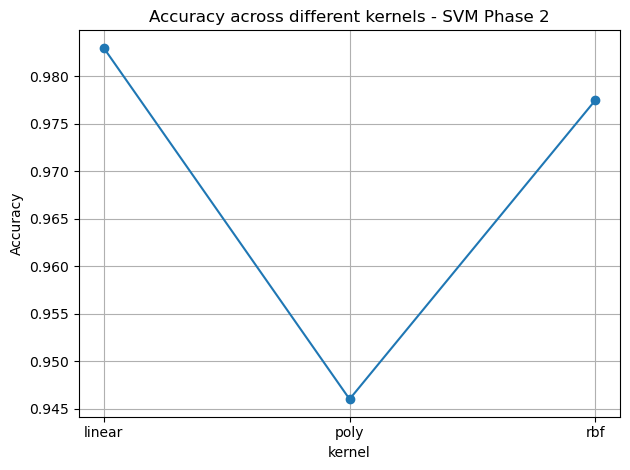

Kernel=rbf , C= 0.01, Gamma=scale, Accuracy=0.9135
Kernel=rbf , C= 0.1, Gamma=scale, Accuracy=0.9570
Kernel=rbf , C= 1, Gamma=scale, Accuracy=0.9775
Kernel=rbf , C= 5, Gamma=scale, Accuracy=0.9810
Kernel=rbf , C= 10, Gamma=scale, Accuracy=0.9810


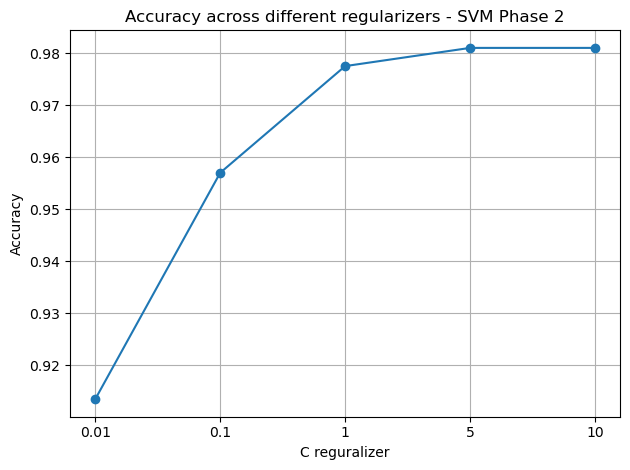

Kernel=rbg, C= 1, Gamma=0.01, Accuracy=0.9315
Kernel=rbg, C= 1, Gamma=0.1, Accuracy=0.9730
Kernel=rbg, C= 1, Gamma=scale, Accuracy=0.9775


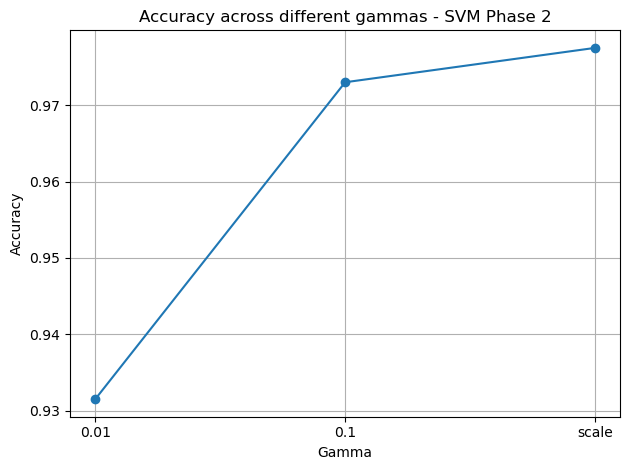

In [13]:
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

kernel_exp=['linear','poly','rbf']
c_regularizer=[0.01,0.1,1,5,10]
gamma_exp=[0.01,0.1,'scale',]
acc_kernel=[]
acc_c=[]
acc_gamma=[]
print("SVM Parameter tuning")
for k in kernel_exp:
          
    svm = SVC(kernel=k,C=1,gamma='scale')   
    svm.fit(X_train_tfidf, y_train)
    svm_preds = svm.predict(X_test_tfidf)

    acc = accuracy_score(y_test, svm_preds)
    acc_kernel.append(acc)
    print(f"Kernel={k:<6} , C= 1, Gamma=scale, Accuracy={acc:.4f}")


plt.figure()
plt.title("Accuracy across different kernels - SVM Phase 2")
plt.plot([str(k) for k in kernel_exp],acc_kernel,marker="o")
plt.xlabel("kernel")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

for c in c_regularizer:
          
    svm = SVC(kernel='rbf',C=c,gamma='scale')   
    svm.fit(X_train_tfidf, y_train)
    svm_preds = svm.predict(X_test_tfidf)

    acc = accuracy_score(y_test, svm_preds)
    acc_c.append(acc)
    print(f"Kernel=rbf , C= {c}, Gamma=scale, Accuracy={acc:.4f}")

plt.figure()
plt.title("Accuracy across different regularizers - SVM Phase 2")
plt.plot([str(c) for c in c_regularizer],acc_c,marker="o")
plt.xlabel("C reguralizer")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

for g in gamma_exp:
          
    svm = SVC(kernel='rbf',C=1,gamma=g)   
    svm.fit(X_train_tfidf, y_train)
    svm_preds = svm.predict(X_test_tfidf)

    acc = accuracy_score(y_test, svm_preds)
    acc_gamma.append(acc)
    print(f"Kernel=rbg, C= 1, Gamma={g}, Accuracy={acc:.4f}")

plt.figure()
plt.title("Accuracy across different gammas - SVM Phase 2")
plt.plot([str(g) for g in gamma_exp],acc_gamma,marker="o")
plt.xlabel("Gamma")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()